|<h2>Book:</h2>|<h1><a href="https://open.substack.com/pub/mikexcohen/p/llm-breakdown-16-tokenization-words" target="_blank">50 ML projects to understand LLMs</a></h1>|
|-|:-:|
|<h2>Project:</h2>|<h1><b>[10] Sequential number cosine similarity</b></h1>|
|<h2>Author:<h2>|<h1>Mike X Cohen, <a href="https://sincxpress.com" target="_blank">sincxpress.com</a></h1>|

<br>

<i>Using the code without reading the book may lead to confusion or errors.</i>

In [1]:
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn.functional as F

In [2]:
### matplotlib adjustments (commented lines are for dark mode)

# svg plots (higher-res)
import matplotlib_inline.backend_inline
matplotlib_inline.backend_inline.set_matplotlib_formats('svg')

plt.rcParams.update({
    # 'figure.facecolor': '#282a2c',
    # 'figure.edgecolor': '#282a2c',
    # 'axes.facecolor':   '#282a2c',
    # 'axes.edgecolor':   '#DDE2F4',
    # 'axes.labelcolor':  '#DDE2F4',
    # 'xtick.color':      '#DDE2F4',
    # 'ytick.color':      '#DDE2F4',
    # 'text.color':       '#DDE2F4',
    'axes.spines.right': False,
    'axes.spines.top':   False,
    'axes.titleweight': 'bold',
    'axes.labelweight': 'bold',
    'savefig.dpi':300,
})

# **Part 1: Token counts of numbers**

In [3]:
# GPT2 tokenizer and model
from transformers import AutoTokenizer,AutoModel
model = AutoModel.from_pretrained('gpt2')
tokenizer = AutoTokenizer.from_pretrained('gpt2')

# the embeddings matrix
embeddings = model.wte.weight.detach()

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

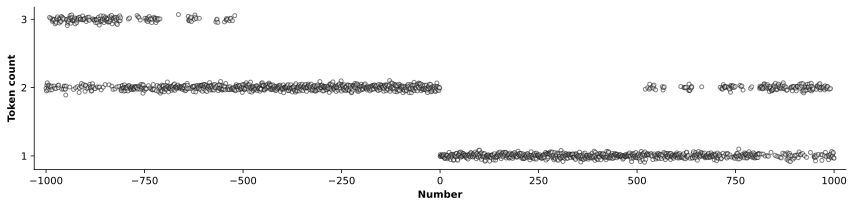

In [4]:
# the numbers to tokenize
numbers = np.arange(-1000,1001)

# initializations
num_tokens = np.zeros(len(numbers),dtype=int)
token_idx = []

# loop over tokens
for i in range(len(numbers)):

  # tokenize
  t = tokenizer.encode(str(numbers[i]))

  # store indices and length
  token_idx.append(t)
  num_tokens[i] = len(t)


plt.figure(figsize=(12,3))
plt.plot(numbers,num_tokens+np.random.normal(0,.03,len(numbers)),'ko',markerfacecolor='w',markersize=4,alpha=.5)
plt.gca().set(xlabel='Number',ylabel='Token count',yticks=np.unique(num_tokens),
              xlim=[numbers[0]-30,numbers[-1]+30])

plt.tight_layout()
plt.savefig('ch3_proj10_part1a.png')
plt.show()

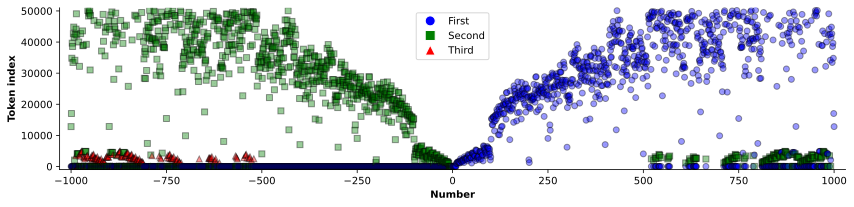

In [5]:
plt.figure(figsize=(12,3))
colord = 'bgr'
shape = 'os^'

# loop over tokens
for i in range(len(numbers)):

  # extract the token indices for this number
  t = token_idx[i]

  # plot them
  for ti in range(len(t)):
    plt.plot(numbers[i],t[ti],'k',marker=shape[ti],markerfacecolor=colord[ti],
             markersize=6,alpha=.4,linewidth=.4)


# hacky legend solution (plot with alpha=0)
for i in range(3):
  plt.plot(0,0,'w',marker=shape[i],markerfacecolor=colord[i],
             markersize=10,alpha=0,linewidth=.5,label=['First','Second','Third'][i])
h = plt.legend()
for e in h.legend_handles: e.set_alpha(1)

plt.gca().set(xlabel='Number',ylabel='Token index',ylim=[-1000,51000],xlim=[numbers[0]-30,numbers[-1]+30])

plt.tight_layout()
plt.savefig('ch3_proj10_part1b.png')
plt.show()

# **Part 2: Opposite sign, equal token indices**

In [6]:
# initialize
matches_count = np.zeros(1000)
matches_vals = np.zeros(1000)

for i in range(1000):

  # confirm the digit pairing and token count
  n = f'({numbers[i]:>5},{numbers[-i-1]:>4})'
  t = f'({num_tokens[i]-1},{num_tokens[-i-1]})'

  # see if they match
  matches_count[i] = (num_tokens[i]-1) == num_tokens[-i-1]
  matches_vals[i] = token_idx[i][1:] == token_idx[-i-1]

  # for confirmation during code development
  # print(n,t)

matches_count.sum(), matches_vals.sum()

(np.float64(1000.0), np.float64(1000.0))

# **Part 3: Successive digit cosine similarity**

In [7]:
# confirm that digits are single-token
for i in range(11):
  print(f'The token(s) for "{i}" are: {tokenizer.encode(str(i))}')

The token(s) for "0" are: [15]
The token(s) for "1" are: [16]
The token(s) for "2" are: [17]
The token(s) for "3" are: [18]
The token(s) for "4" are: [19]
The token(s) for "5" are: [20]
The token(s) for "6" are: [21]
The token(s) for "7" are: [22]
The token(s) for "8" are: [23]
The token(s) for "9" are: [24]
The token(s) for "10" are: [940]


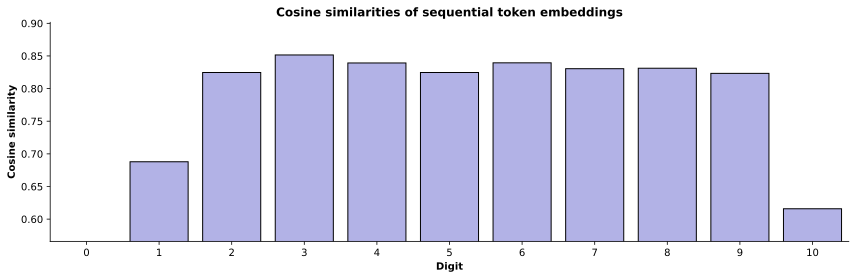

In [8]:
# tokenize the digits
tokens = [tokenizer.encode(str(i))[0] for i in range(11)]

# initialize cosine similarity
cossim = np.full(len(tokens),np.nan)

# calculate cosine similarity for successive digit pairs
for ti in range(1,len(tokens)):
  v1 = embeddings[tokens[ti],:]
  v2 = embeddings[tokens[ti-1],:]
  cossim[ti] = torch.sum(v1*v2) / torch.sqrt( torch.sum(v1**2)*torch.sum(v2**2) )


# plot!
plt.figure(figsize=(12,4))
plt.bar(np.arange(len(cossim)),cossim,facecolor=[.7,.7,.9],edgecolor='k')
plt.gca().set(xticks=range(len(tokens)),xticklabels=[tokenizer.decode(t) for t in tokens],
              xlabel='Digit',ylabel='Cosine similarity',
              xlim=[-.5,len(tokens)-.5],ylim=[np.nanmin(cossim)-.05,np.nanmax(cossim)+.05])

plt.title('Cosine similarities of sequential token embeddings',fontweight='bold')

plt.tight_layout()
plt.savefig('ch3_proj10_part3.png')
plt.show()

# **Part 4: All to all number similarities**

In [9]:
# tokenize the numbers
nums = [str(i) for i in range(10)] + [str(i*10) for i in range(1,11)]
tokens = tokenizer.encode(nums)
tokens = [t[0] for t in tokens] # list from list of lists

# confirm single tokens
for t in tokens:
  print(f'{t:5} is "{tokenizer.decode(t)}"')

   15 is "0"
   16 is "1"
   17 is "2"
   18 is "3"
   19 is "4"
   20 is "5"
   21 is "6"
   22 is "7"
   23 is "8"
   24 is "9"
  940 is "10"
 1238 is "20"
 1270 is "30"
 1821 is "40"
 1120 is "50"
 1899 is "60"
 2154 is "70"
 1795 is "80"
 3829 is "90"
 3064 is "100"


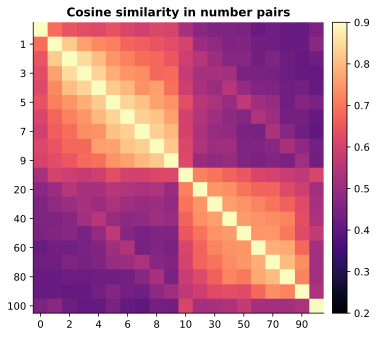

In [10]:
# cosine similarity matrix
E = embeddings[tokens,:]
E_norm = F.normalize(E,p=2,dim=1)
csM = E_norm @ E_norm.T

# visualize
plt.imshow(csM,vmin=.2,vmax=.9,cmap='magma')
plt.gca().set(xticks=range(0,len(nums),2),xticklabels=nums[::2],
              yticks=range(1,len(nums),2),yticklabels=nums[1::2],
              title='Cosine similarity in number pairs')
plt.colorbar(pad=.02)

plt.tight_layout()
plt.savefig('ch3_proj10_part4.png')
plt.show()

In [15]:
import pandas as pd

single_token_rows = []
multiple_token_rows = []

for number in range(1, 1000001):

    number_text = str(number)

    token_indices = tokenizer.encode(
        number_text,
        add_special_tokens=False
    )

    token_texts = [
        tokenizer.decode([index])
        for index in token_indices
    ]

    if len(token_indices) == 1:

        single_token_rows.append({
            'Number': number,
            'Token index': token_indices[0],
            'Token': token_texts[0]
        })

    else:

        multiple_token_rows.append({
            'Number': number,
            'Number of tokens': len(token_indices),
            'Token indices': token_indices,
            'Tokens': token_texts
        })


# Números de 10000 até 1 representados por um único token
single_token_table = (
    pd.DataFrame(single_token_rows)
    .sort_values('Number', ascending=False)
    .reset_index(drop=True)
)


# Números de 1 até 10000 representados por múltiplos tokens
multiple_token_table = (
    pd.DataFrame(multiple_token_rows)
    .sort_values('Number', ascending=True)
    .reset_index(drop=True)
)

In [16]:
print('NÚMEROS REPRESENTADOS POR UM ÚNICO TOKEN')
display(single_token_table)

print('NÚMEROS REPRESENTADOS POR MAIS DE UM TOKEN')
display(multiple_token_table)

NÚMEROS REPRESENTADOS POR UM ÚNICO TOKEN


,Number,Token index,Token
0,200000,33470,200000
1,76561,48527,76561
2,70710,42877,70710
3,20439,47936,20439
4,10000,49388,10000
...,...,...,...
906,5,20,5
907,4,19,4
908,3,18,3
909,2,17,2


NÚMEROS REPRESENTADOS POR MAIS DE UM TOKEN


,Number,Number of tokens,Token indices,Tokens
0,521,2,"[20, 2481]","[5, 21]"
1,527,2,"[20, 1983]","[5, 27]"
2,531,2,"[20, 3132]","[5, 31]"
3,532,2,"[20, 2624]","[5, 32]"
4,534,2,"[20, 2682]","[5, 34]"
...,...,...,...,...
999084,999996,2,"[24214, 4846]","[9999, 96]"
999085,999997,2,"[24214, 5607]","[9999, 97]"
999086,999998,2,"[24214, 4089]","[9999, 98]"
999087,999999,2,"[24214, 2079]","[9999, 99]"


In [17]:
print(f'Um único token: {len(single_token_table):,}')
print(f'Mais de um token: {len(multiple_token_table):,}')
print(f'Total analisado: {len(single_token_table) + len(multiple_token_table):,}')

Um único token: 911
Mais de um token: 999,089
Total analisado: 1,000,000
